# Challenge 2 — Pipeline 2: Predicción y visualización
## Caso: minería de asteroides | Sesión 7 de Machine Learning (UPCH)

**Pregunta:** ¿Cómo varía el **costo simulado** de una misión hipotética de exploración de asteroides según su duración, masa de equipo, complejidad técnica y autonomía?

**Tarea:** aprendizaje supervisado → **regresión numérica**. La NASA distingue la exploración científica de asteroides de una actividad de extracción comercial establecida [1].

**Modelos vistos en clase:**
1. Regresión lineal (`LinearRegression`).
2. Regresión no lineal mediante regresión polinómica de grado 2 (`PolynomialFeatures` + `make_pipeline`).

> ⚠️ **Advertencia metodológica:** el dataset contiene **240 escenarios 100 % sintéticos**. Sus costos y la fórmula generadora fueron inventados para practicar ML; no son datos reales, presupuestos de NASA, ni una estimación de rentabilidad comercial. El Pipeline 1 del Challenge 2 sobre estrategias de inversión sirve de contexto, pero una predicción de costos sintéticos **no** determina por sí sola si invertir es viable.

**Estructura del pipeline:** problema → datos → preparación → entrenamiento → predicción → evaluación → visualización → interpretación.

### 1. Librerías
Se utilizan `pandas`, `numpy`, `matplotlib` y `scikit-learn`, al nivel de los laboratorios. Las métricas MAE, RMSE y R² permiten evaluar valores numéricos; **accuracy** se reserva para clasificación.

In [1]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Librerías importadas correctamente")

Librerías importadas correctamente


### 2. Cargar el dataset del paso 7
El notebook funciona de dos maneras:
- Si encuentra el CSV junto al notebook o dentro de `data/`, lo utiliza directamente.
- Si no lo encuentra (por ejemplo, al subir **solo el notebook a Colab**), vuelve a generar **exactamente el dataset didáctico del paso 7**, usando la misma semilla y los mismos coeficientes. Guarda una copia del CSV en `data/`.

La alternativa de regeneración es para facilitar la reproducción, **no** convierte los datos en reales.

In [2]:
SEED_DATOS = 2026
COLUMNAS_X = ["duracion_meses", "masa_equipo_kg", "complejidad_tecnica", "autonomia_pct"]
COLUMNA_Y = "costo_simulado_musd"

rutas = [
    Path("data/escenarios_costos_SINTETICOS.csv"),
    Path("escenarios_costos_SINTETICOS.csv"),
]
archivo = next((p for p in rutas if p.exists()), None)

if archivo is not None:
    df = pd.read_csv(archivo)
    print("CSV encontrado:", archivo)
else:
    # Misma fórmula y semilla que generar_dataset.py del paso 7.
    rng = random.Random(SEED_DATOS)
    registros = []
    for i in range(1, 241):
        meses = rng.randint(8, 60)
        masa = rng.randint(80, 600)
        complejidad = rng.randint(1, 5)
        autonomia = rng.randint(25, 95)
        ruido = rng.gauss(0, 9.0)
        costo = (30.0 + 0.65 * meses + 0.11 * masa
                 + 12.0 * complejidad - 0.10 * autonomia
                 + 0.015 * meses**2 + 0.00015 * masa**2 + ruido)
        registros.append({
            "id_escenario": f"SIM-{i:03}",
            "duracion_meses": meses,
            "masa_equipo_kg": masa,
            "complejidad_tecnica": complejidad,
            "autonomia_pct": autonomia,
            "costo_simulado_musd": round(max(1.0, costo), 2)
        })
    df = pd.DataFrame(registros)
    Path("data").mkdir(exist_ok=True)
    df.to_csv("data/escenarios_costos_SINTETICOS.csv", index=False)
    print("CSV no encontrado: se regeneró el dataset SINTÉTICO del paso 7.")

# Comprobaciones sencillas del dataset
if len(df) != 240:
    raise ValueError("El dataset debe contener 240 registros.")

for columna in COLUMNAS_X + [COLUMNA_Y, "id_escenario"]:
    if columna not in df.columns:
        raise ValueError("Falta la columna: " + columna)

if df[COLUMNAS_X + [COLUMNA_Y]].isna().sum().sum() > 0:
    raise ValueError("El dataset contiene valores faltantes.")

if df["id_escenario"].duplicated().sum() > 0:
    raise ValueError("Hay identificadores repetidos.")
print("Dimensiones:", df.shape)
display(df.head())

CSV no encontrado: se regeneró el dataset SINTÉTICO del paso 7.
Dimensiones: (240, 6)


,id_escenario,duracion_meses,masa_equipo_kg,complejidad_tecnica,autonomia_pct,costo_simulado_musd
0,SIM-001,15,407,5,90,150.35
1,SIM-002,22,510,5,95,179.41
2,SIM-003,54,582,5,81,276.35
3,SIM-004,15,374,1,82,121.44
4,SIM-005,8,582,3,51,175.24


### 3. Exploración y verificación de variables
La variable objetivo **Y** es una cantidad continua: millones de USD *hipotéticos*. `id_escenario` es solo un identificador, por lo tanto **no se utiliza para predecir**.

Tipos de datos:
id_escenario            object
duracion_meses           int64
masa_equipo_kg           int64
complejidad_tecnica      int64
autonomia_pct            int64
costo_simulado_musd    float64
dtype: object

Valores faltantes:
id_escenario           0
duracion_meses         0
masa_equipo_kg         0
complejidad_tecnica    0
autonomia_pct          0
costo_simulado_musd    0
dtype: int64

Resumen estadístico:


,duracion_meses,masa_equipo_kg,complejidad_tecnica,autonomia_pct,costo_simulado_musd
count,240.00,240.00,240.00,240.00,240.00
mean,34.06,337.69,3.22,62.22,163.44
std,15.49,158.17,1.43,21.07,47.00
min,8.00,80.00,1.00,26.00,60.33
25%,20.00,202.00,2.00,43.00,131.70
50%,35.00,315.00,3.00,63.00,162.44
75%,47.25,489.00,5.00,83.00,188.14
max,60.00,600.00,5.00,95.00,289.36


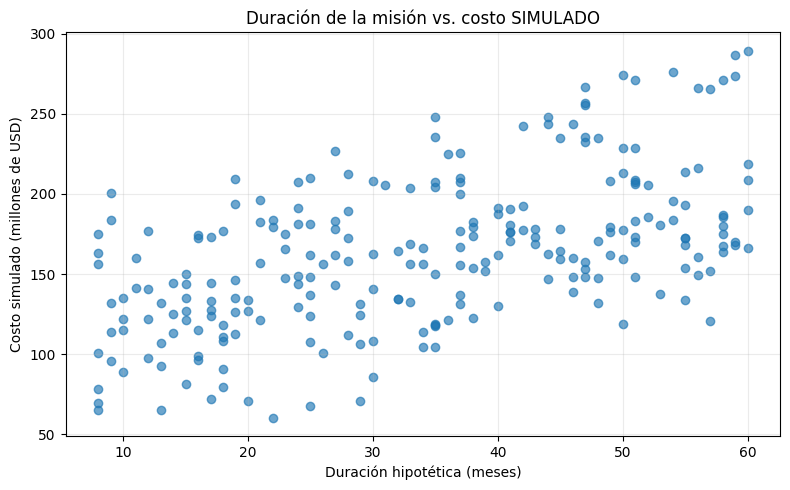

In [3]:
print("Tipos de datos:")
print(df.dtypes)
print("\nValores faltantes:")
print(df.isna().sum())
print("\nResumen estadístico:")
display(df[COLUMNAS_X + [COLUMNA_Y]].describe().round(2))

# Crear las carpetas del repositorio para los resultados
Path("images").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)
plt.figure(figsize=(8, 5))
plt.scatter(df["duracion_meses"], df[COLUMNA_Y], alpha=0.65)
plt.title("Duración de la misión vs. costo SIMULADO")
plt.xlabel("Duración hipotética (meses)")
plt.ylabel("Costo simulado (millones de USD)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("images/pipeline2_dispersion_sintetica.png", dpi=170)
plt.show()

### 4. Definir X e Y y dividir datos
- **Entradas X:** meses, masa, complejidad, autonomía.
- **Objetivo Y:** costo simulado.
- **Entrenamiento:** 80 % (192 filas).
- **Prueba:** 20 % (48 filas), separadas **antes** de entrenar para evaluar ejemplos no vistos.

Como los escenarios son sintéticos e independientes, utilizamos una división aleatoria reproducible (`random_state=42`).

In [4]:
X = df[COLUMNAS_X]
y = df[COLUMNA_Y]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Entrenamiento:", len(X_train), "registros")
print("Prueba:", len(X_test), "registros")
if X_train.index.isin(X_test.index).any():
    raise ValueError("Hay registros repetidos entre entrenamiento y prueba.")

Entrenamiento: 192 registros
Prueba: 48 registros


### 5. Entrenar los modelos vistos en clase
**Regresión lineal:** modela el costo como combinación lineal de las cuatro variables [2].

**Regresión no lineal (polinómica, grado 2):** amplía las variables con términos cuadrados e interacciones; permite representar curvas [3]. `PolynomialFeatures` se ajusta únicamente sobre entrenamiento mediante `make_pipeline`, evitando usar información del conjunto de prueba durante el entrenamiento.

El objetivo es comparar modelos, **no asumir** que el más complejo siempre es mejor.

In [5]:
modelo_lineal = LinearRegression()
modelo_polinomico = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

modelo_lineal.fit(X_train, y_train)
modelo_polinomico.fit(X_train, y_train)

pred_lineal = modelo_lineal.predict(X_test)
pred_polinomico = modelo_polinomico.predict(X_test)

print("Regresión lineal y polinómica entrenadas correctamente")

Regresión lineal y polinómica entrenadas correctamente


### 6. Evaluar y comparar
Según la documentación de evaluación de scikit-learn, MAE, RMSE y R² son métricas adecuadas para regresión [4].

**MAE**: error absoluto medio en millones de USD hipotéticos (**menor es mejor**).  
**RMSE**: raíz del error cuadrático medio; penaliza más los errores grandes (**menor es mejor**).  
**R²**: proporción de variabilidad explicada respecto a una referencia constante (**mayor suele ser mejor**; puede ser negativo).

Se añade una **referencia simple** que siempre predice el promedio de entrenamiento. Así comprobamos que el modelo supera una alternativa trivial.

In [6]:
def metricas(nombre, real, pred):
    return {
        "Modelo": nombre,
        "MAE": mean_absolute_error(real, pred),
        "RMSE": np.sqrt(mean_squared_error(real, pred)),
        "R2": r2_score(real, pred),
    }

pred_referencia = np.full(len(y_test), y_train.mean())
resultados = pd.DataFrame([
    metricas("Referencia (promedio)", y_test, pred_referencia),
    metricas("Regresión lineal", y_test, pred_lineal),
    metricas("Regresión polinómica (grado 2)", y_test, pred_polinomico),
])

print("Evaluación exclusiva sobre los datos de prueba:")
display(resultados.round(4))

comparables = resultados[resultados["Modelo"] != "Referencia (promedio)"]
mejor_nombre = comparables.sort_values("RMSE").iloc[0]["Modelo"]
mejor_modelo = modelo_polinomico if "polinómica" in mejor_nombre else modelo_lineal
mejor_pred = pred_polinomico if "polinómica" in mejor_nombre else pred_lineal
print("Menor RMSE en prueba:", mejor_nombre)
print("ADVERTENCIA: este resultado solo es válido para los escenarios sintéticos.")

Evaluación exclusiva sobre los datos de prueba:


,Modelo,MAE,RMSE,R2
0,Referencia (promedio),40.1017,49.9255,-0.0032
1,Regresión lineal,7.0594,8.6381,0.9700
2,Regresión polinómica (grado 2),6.7215,8.3293,0.9721


Menor RMSE en prueba: Regresión polinómica (grado 2)
ADVERTENCIA: este resultado solo es válido para los escenarios sintéticos.


### 7. Visualización comparativa de modelos
El gráfico muestra **errores de predicción** en el conjunto de prueba. El modelo con menor RMSE no necesariamente es el mejor para costos reales, porque las relaciones de este dataset fueron construidas artificialmente.

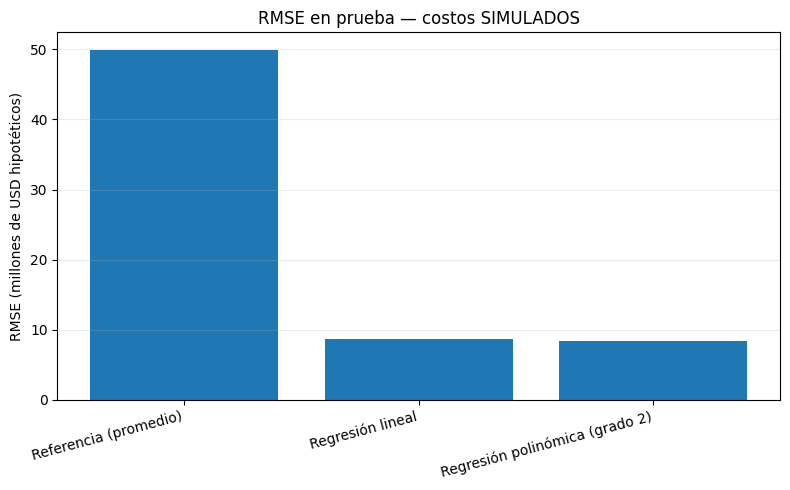

In [7]:
plt.figure(figsize=(8, 5))
plt.bar(resultados["Modelo"], resultados["RMSE"])
plt.title("RMSE en prueba — costos SIMULADOS")
plt.ylabel("RMSE (millones de USD hipotéticos)")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("images/pipeline2_comparacion_rmse.png", dpi=170)
plt.show()

### 8. Visualización de valores reales sintéticos frente a predichos
Si un punto está cerca de la diagonal, la predicción se aproxima al valor **observado en el simulador**, no a un costo observado en el mundo real.

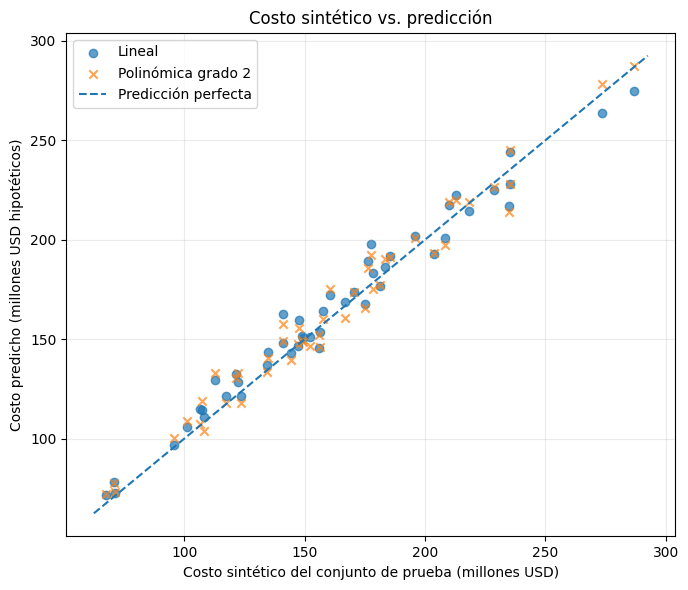

In [8]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, pred_lineal, alpha=0.7, label="Lineal")
plt.scatter(y_test, pred_polinomico, alpha=0.7, label="Polinómica grado 2", marker="x")
lim_inf = min(y_test.min(), pred_lineal.min(), pred_polinomico.min()) - 5
lim_sup = max(y_test.max(), pred_lineal.max(), pred_polinomico.max()) + 5
plt.plot([lim_inf, lim_sup], [lim_inf, lim_sup], linestyle="--", label="Predicción perfecta")
plt.xlabel("Costo sintético del conjunto de prueba (millones USD)")
plt.ylabel("Costo predicho (millones USD hipotéticos)")
plt.title("Costo sintético vs. predicción")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("images/pipeline2_real_vs_predicho.png", dpi=170)
plt.show()

### 9. Analizar los residuos
**Residuo = valor del simulador − predicción**. Los residuos deberían situarse alrededor de cero sin patrones sistemáticos fuertes. Este análisis es orientativo, dado que el conjunto de datos procede de una función creada para la práctica.

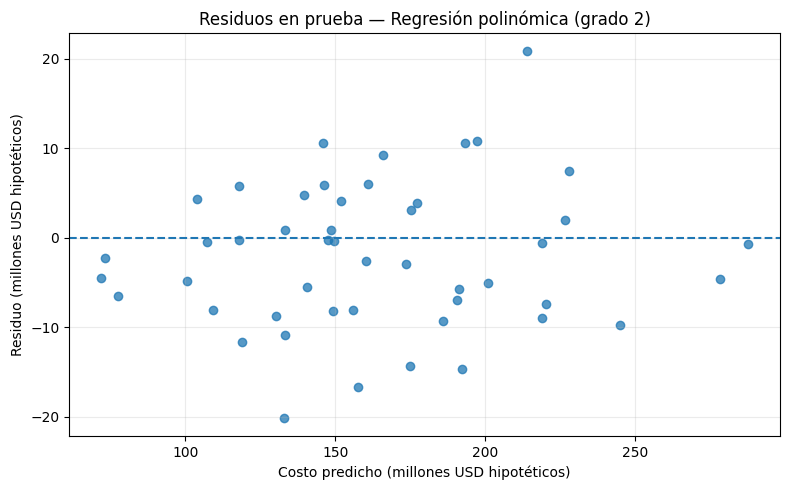

In [9]:
residuos = y_test.to_numpy() - mejor_pred
plt.figure(figsize=(8, 5))
plt.scatter(mejor_pred, residuos, alpha=0.75)
plt.axhline(0, linestyle="--")
plt.title(f"Residuos en prueba — {mejor_nombre}")
plt.xlabel("Costo predicho (millones USD hipotéticos)")
plt.ylabel("Residuo (millones USD hipotéticos)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("images/pipeline2_residuos.png", dpi=170)
plt.show()

### 10. Curva interpretativa de la duración
Para comparar cómo se comportan los modelos al cambiar **solo la duración**, mantenemos constantes las otras tres variables (masa = 350 kg, complejidad = 3 y autonomía = 70 %). Es una visualización *condicional del modelo*, no una regla científica sobre costos de minería espacial.

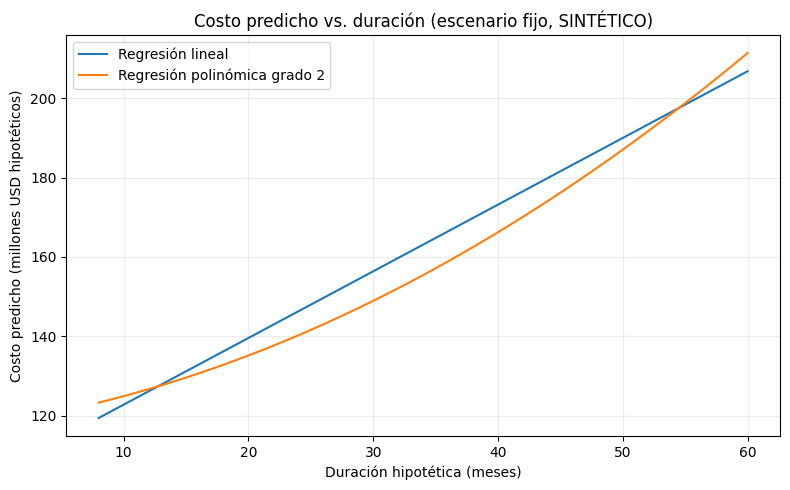

In [10]:
meses = np.arange(8, 61)
casos_curva = pd.DataFrame({
    "duracion_meses": meses,
    "masa_equipo_kg": 350,
    "complejidad_tecnica": 3,
    "autonomia_pct": 70,
})
curva_lineal = modelo_lineal.predict(casos_curva)
curva_polinomica = modelo_polinomico.predict(casos_curva)

plt.figure(figsize=(8, 5))
plt.plot(meses, curva_lineal, label="Regresión lineal")
plt.plot(meses, curva_polinomica, label="Regresión polinómica grado 2")
plt.title("Costo predicho vs. duración (escenario fijo, SINTÉTICO)")
plt.xlabel("Duración hipotética (meses)")
plt.ylabel("Costo predicho (millones USD hipotéticos)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("images/pipeline2_curva_duracion.png", dpi=170)
plt.show()

### 11. Estimar un nuevo escenario (didáctico)
El escenario de prueba está **dentro de los intervalos** utilizados para generar los datos. La predicción se presenta solo para demostrar el procedimiento, no como presupuesto para una misión real.

In [11]:
nuevo_escenario = pd.DataFrame([{
    "duracion_meses": 24,
    "masa_equipo_kg": 350,
    "complejidad_tecnica": 3,
    "autonomia_pct": 70,
}])

nuevo_lineal = float(modelo_lineal.predict(nuevo_escenario)[0])
nuevo_polinomico = float(modelo_polinomico.predict(nuevo_escenario)[0])
display(nuevo_escenario)
print(f"Regresión lineal: {nuevo_lineal:.2f} millones de USD HIPOTÉTICOS")
print(f"Regresión polinómica: {nuevo_polinomico:.2f} millones de USD HIPOTÉTICOS")

,duracion_meses,masa_equipo_kg,complejidad_tecnica,autonomia_pct
0,24,350,3,70


Regresión lineal: 146.30 millones de USD HIPOTÉTICOS
Regresión polinómica: 140.25 millones de USD HIPOTÉTICOS


### 12. Conclusiones y limitaciones
1. Ambas regresiones usan **aprendizaje supervisado** porque la variable objetivo es un valor numérico conocido en los escenarios sintéticos.
2. La regresión lineal supone una combinación lineal de las entradas; la polinómica de grado 2 puede capturar curvaturas e interacciones.
3. Las métricas se calcularon sobre **48 escenarios reservados para prueba**, no sobre los mismos registros usados para ajustar los modelos.
4. Si la polinómica obtiene menor error, ello es esperable: **la función que creó los datos sintéticos contiene explícitamente términos cuadrados**. No debe presentarse como hallazgo sobre costos reales.
5. Este pipeline **no clasifica una inversión como viable o inviable**. El primer pipeline representa decisiones cualitativas bajo restricciones; la regresión aporta solo un ejemplo didáctico de estimación cuantitativa.
6. Para pasar a conclusiones reales se necesitarían costos observados fiables, variables operativas pertinentes y validación independiente.

**Procedencia de los datos:** los 240 escenarios y la fórmula generadora son elaboraciones sintéticas para este trabajo. La infografía del caso se utiliza como contexto, no como validación empírica de los costos.

### 13. Referencias (formato IEEE)

[1] NASA, “Is NASA Mining Asteroids? We Asked a NASA Scientist: Episode 41,” 28 jun. 2023. [En línea]. Disponible en: https://www.nasa.gov/general/is-nasa-mining-asteroids-we-asked-a-nasa-scientist-episode-41/. [Accedido: 14-oct-2026].

[2] scikit-learn developers, “1.1. Linear Models,” *scikit-learn User Guide*. [En línea]. Disponible en: https://scikit-learn.org/stable/modules/linear_model.html. [Accedido: 14-oct-2026].

[3] scikit-learn developers, “PolynomialFeatures,” *scikit-learn API Reference*. [En línea]. Disponible en: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html. [Accedido: 14-oct-2026].

[4] scikit-learn developers, “3.4. Metrics and scoring: Quantifying the quality of predictions,” *scikit-learn User Guide*. [En línea]. Disponible en: https://scikit-learn.org/stable/modules/model_evaluation.html. [Accedido: 14-oct-2026].